# 2019 L-band cross-correlation with multiscale PCA (mPCA)

This recipe repeats the [2019 L-band cross-correlation](2019_Lband.ipynb) (MeerKLASS 2019 L-band × WiggleZ)
with the **multiscale PCA** (mPCA) foreground cleaning of
[Carucci et al. 2025, A&A 703, A222](https://doi.org/10.1051/0004-6361/202453461),
available as `meer21cm.mpca.mpca_clean`.

Standard PCA finds one set of foreground modes along frequency for all angular scales. mPCA first splits each
channel map into a **coarse** (large angular scales) and a **fine** (small angular scales) part with a starlet
wavelet transform, and runs a separate PCA on each, removing $N_{\rm L}$ modes from the coarse part and
$N_{\rm S}$ from the fine part:

$$\mathbf{d}_{\rm clean} = (I - A_{\rm L}A_{\rm L}^T)\,\mathbf{d}_{\rm coarse} + (I - A_{\rm S}A_{\rm S}^T)\,\mathbf{d}_{\rm fine}.$$

Large scales carry most of the foreground power and the instrumental systematics, small scales are closer to
thermal noise, so each scale gets its own level of cleaning. In the paper, mPCA with $(N_{\rm L}, N_{\rm S}) = (4, 8)$
gave the most significant detection of the cross-correlation (5.8σ, against 3.3σ for PCA with $N_{\rm fg} = 4$).

Data: the MeerKLASS 2019 maps from [meerklass.org](https://meerklass.org/data.html), and the WiggleZ 11h-region
galaxy catalogue `reg11data.dat` from the public WiggleZ release ([Zenodo](https://zenodo.org/record/33470)), as in
the 2019 L-band recipe. For the galaxy selection function, the WiggleZ selection on the 2019 map voxels used in the
paper (`WiggleZ_selection.npy`) if available, otherwise one built from the public random catalogues
`reg11rand*.dat` (same Zenodo release). Set-up as in the paper, and different from the 2019 L-band recipe:

- all 250 channels and the paper's "Conservative Footprint" (CF, stored in the pickle);
- galaxy field $F = D - \alpha R$ with randoms drawn from the selection function, and FKP weights with
  $P_0 = 1000\,h^{-3}{\rm Mpc}^3$;
- a Tukey ($\alpha = 0.5$) taper across the sky, on HI, galaxies and randoms;
- radial down-resolution 2 instead of 10.

**No transfer function.** All amplitudes below are therefore lower limits, for PCA and
mPCA alike. Errors are the Gaussian ones of the 2019 L-band recipe, which underestimate the real scatter.

In [1]:
import glob
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from scipy.signal.windows import tukey
from meer21cm import PowerSpectrum
from meer21cm.util import pca_clean, radec_to_indx
from meer21cm.mpca import mpca_clean, starlet_split
from meer21cm.telescope import dish_beam_sigma
from meer21cm.plot import plot_map, plot_eigenspectrum

In [2]:
file_dir = './'
pickle_file = file_dir + 'MK_2019_maps.pkl'                    # MeerKLASS 2019 maps (meerklass.org)
zenodo_dir = file_dir + 'data_from_zenodo/'                    # public WiggleZ release (Zenodo)
gal_file = zenodo_dir + 'reg11data.dat'
rand_files = sorted(glob.glob(zenodo_dir + 'reg11rand*.dat'))  # public randoms, used if sel_file is missing
sel_file = file_dir + 'data_from_ilifu/WiggleZ_selection.npy'  # WiggleZ selection on the map voxels (paper)

ps = PowerSpectrum(
    pickle_file=pickle_file,
    beam_model='gaussian',
    beam_type='isotropic',
    band='L',
    survey='meerklass_2019',
)
ps.nu_min = 970e6  # the survey preset starts at 971 MHz and drops the first channel; keep all 250
ps.nu_max = 1024e6
ps.read_from_pickle()
ps.sigma_beam_ch = dish_beam_sigma(13.5, ps.nu)
galcat = np.genfromtxt(gal_file, skip_header=1)  # first line: number of objects; '#' lines are skipped
ra_g, dec_g, z_g = galcat[:, 0], galcat[:, 1], galcat[:, 2]
if not os.path.exists(sel_file):
    randcat = np.concatenate([np.genfromtxt(f, skip_header=1)[:, :3] for f in rand_files])
    ra_r, dec_r, z_r = randcat[:, 0], randcat[:, 1], randcat[:, 2]
    print(len(rand_files), 'public random catalogues')
print(ps.data.shape, 'channels', ps.nu.min() / 1e6, '-', ps.nu.max() / 1e6, 'MHz')

filtering map los
(133, 41, 250) channels 970.94140625 - 1022.978515625 MHz


## Footprint

The CF is a 64 × 17 pixel rectangle in the middle of the scan, where the hits are high and uniform. Map, hits and
pixel weights are set to zero outside it; galaxies and randoms are kept if they fall in a CF pixel and in the
frequency band.
The band is 0.39 < z < 0.46, so only about a fifth of the WiggleZ galaxies in the CF are kept: the map below shows
far fewer galaxies than the one in the 2019 L-band recipe, which plots the whole catalogue at all redshifts.

2127 galaxies in the CF


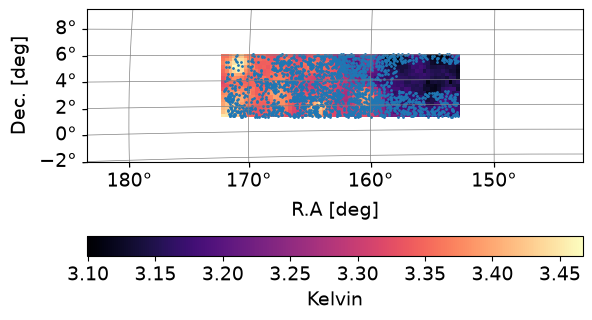

In [3]:
with open(pickle_file, 'rb') as f:
    CF = np.asarray(pickle.load(f)['CF_mask']) > 0
nz = ps.nu.size
CF3 = np.repeat(CF[:, :, None], nz, axis=-1)
ps.data = np.nan_to_num(ps.data) * CF3
ps.counts = np.nan_to_num(ps.counts) * CF3
ps.map_has_sampling = ps.map_has_sampling * CF3
ps.weights_map_pixel = ps.weights_map_pixel * CF3
ps.ra_range = np.array([ps.ra_map[CF].min() - 0.3, ps.ra_map[CF].max() + 0.3])
ps.dec_range = np.array([ps.dec_map[CF].min() - 0.3, ps.dec_map[CF].max() + 0.3])

nu_edges = np.concatenate([[1.5 * ps.nu[0] - 0.5 * ps.nu[1]], (ps.nu[1:] + ps.nu[:-1]) / 2,
                           [1.5 * ps.nu[-1] - 0.5 * ps.nu[-2]]])
z_edges = 1420.405751e6 / nu_edges - 1

def in_footprint(ra, dec, z):
    """Objects in a CF pixel and in the band, with their map pixel (ix, iy) and channel ich."""
    ix, iy = radec_to_indx(ra, dec, ps.wproj)
    ich = np.digitize(1420.405751e6 / (1 + z), nu_edges) - 1
    ok = (ix >= 0) & (ix < CF.shape[0]) & (iy >= 0) & (iy < CF.shape[1]) & (ich >= 0) & (ich < nz)
    inside = np.zeros(ra.size, dtype=bool)
    inside[ok] = CF[ix[ok], iy[ok]]
    return inside, ix[inside], iy[inside], ich[inside]

sel, gx, gy, gch = in_footprint(ra_g, dec_g, z_g)
ps._ra_gal, ps._dec_gal, ps._z_gal = ra_g[sel], dec_g[sel], z_g[sel]
print(sel.sum(), 'galaxies in the CF')

plt.rcParams.update({'font.size': 14})
plot_map(ps.data, ps.wproj, W=CF3, cbar_label='Kelvin')
ax = plt.gca()
ax.scatter(ps.ra_gal, ps.dec_gal, transform=ax.get_transform('world'), s=1)

## The two scales

`starlet_split` returns the starlet scales of the maps (last axis: fine, then coarse; they sum to the input).
The coarse scale is the map smoothed with a B3-spline kernel of ~5 pixels; the fine scale is the rest.
`footprint` tells the transform which pixels are data; the others are filled before the transform and set to zero
after it.

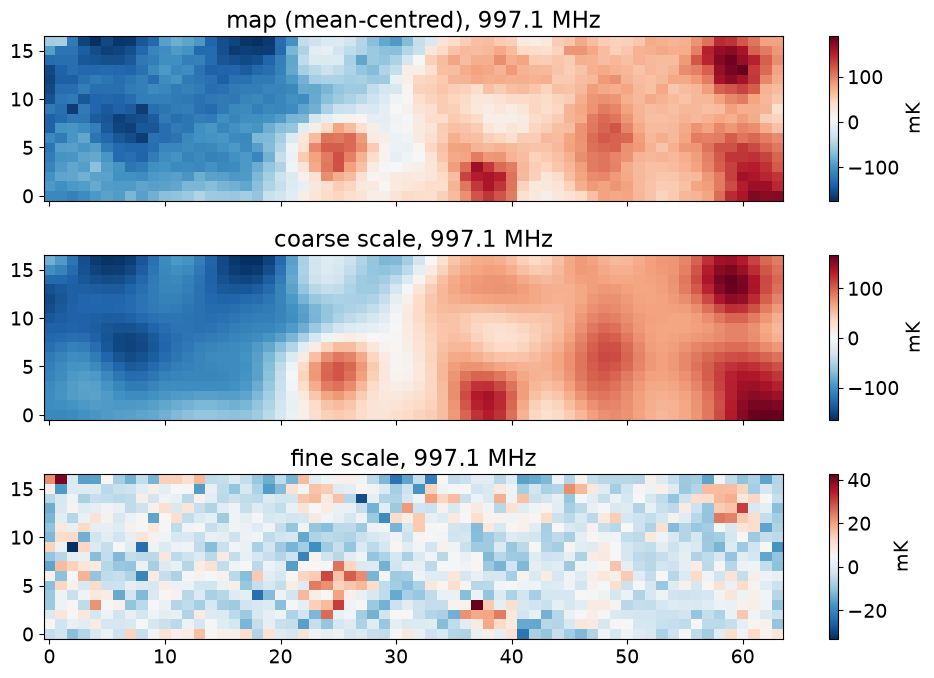

In [4]:
MKmap_orig = ps.data.copy()
ones_cf = CF3.astype(float)
from meer21cm.util import mean_center_signal
map_mc = mean_center_signal(MKmap_orig, ones_cf) * CF3  # mean-centred inside the CF
scales = starlet_split(map_mc, footprint=CF)
fine, coarse = scales[..., 0], scales[..., 1]

ch = nz // 2
sx, sy = np.where(CF)
box = (slice(sx.min(), sx.max() + 1), slice(sy.min(), sy.max() + 1))
fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
for ax, m, t in zip(axes, [map_mc, coarse, fine], ['map (mean-centred)', 'coarse scale', 'fine scale']):
    im = ax.imshow(1e3 * m[box][:, :, ch].T, origin='lower', cmap='RdBu_r', aspect='auto')
    ax.set_title(f'{t}, {ps.nu[ch] / 1e6:.1f} MHz')
    plt.colorbar(im, ax=ax, label='mK')
plt.tight_layout()

Eigenvalues of the frequency-frequency covariance of the full maps and of each scale: most of the foreground power
is in the coarse scale; the fine scale has a shallower spectrum.

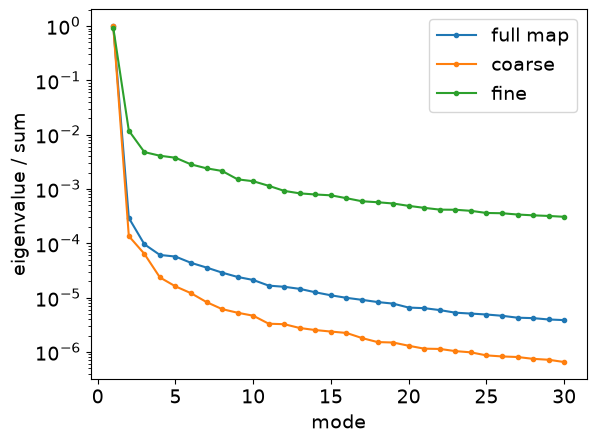

In [5]:
eig = {}
for name, m in [('full map', map_mc), ('coarse', coarse), ('fine', fine)]:
    _, _, eig[name], _ = pca_clean(m, 1, weights=ones_cf, return_analysis=True)
plt.figure()
for name, e in eig.items():
    plt.semilogy(np.arange(1, 31), e[:30] / e.sum(), 'o-', ms=3, label=name)
plt.xlabel('mode')
plt.ylabel('eigenvalue / sum')
plt.legend()

## Cleaning

PCA with $N_{\rm fg} = 4$ and mPCA with $(N_{\rm L}, N_{\rm S}) = (4, 8)$, the paper's best choices, both
mean-centred and unweighted inside the CF (`weights=ones_cf` keeps the zeros outside the CF out of the mean and
of the covariance; for mPCA `footprint=CF` does the same).

Weights: the paper's weighted variants (PCAw, mPCAw) used the hits averaged along frequency, one weight per pixel.
With weights that change along frequency (e.g. `ps.w_HI`, the hits per channel, as in the 2019 L-band recipe) the
covariance, and so the removed modes, are different. Both `pca_clean` and `mpca_clean` accept either.

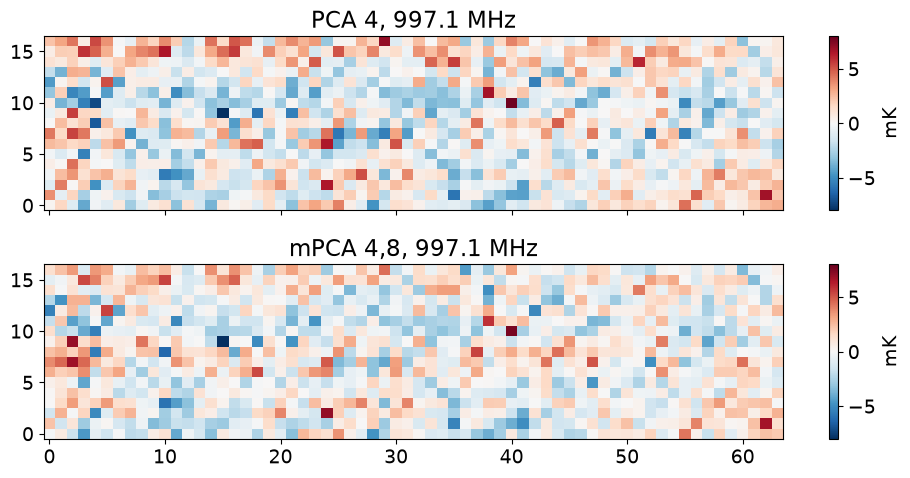

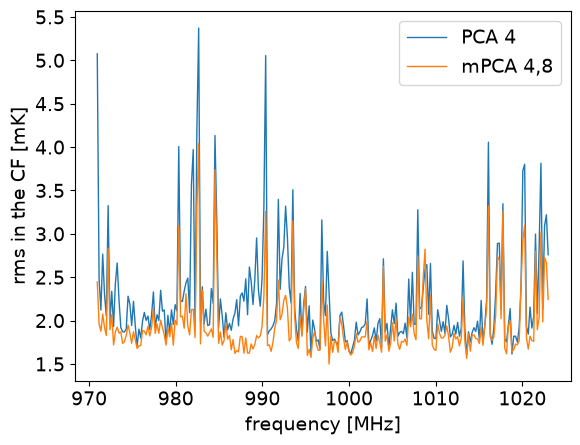

In [6]:
N_fg = 4
N_L, N_S = 4, 8
cleaned = {
    f'PCA {N_fg}': pca_clean(MKmap_orig, N_fg, weights=ones_cf, mean_center=True) * CF3,
    f'mPCA {N_L},{N_S}': mpca_clean(MKmap_orig, N_L, N_S, mean_center=True, footprint=CF),
}
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for ax, (name, m) in zip(axes, cleaned.items()):
    im = ax.imshow(1e3 * m[box][:, :, ch].T, origin='lower', cmap='RdBu_r', aspect='auto', vmin=-8, vmax=8)
    ax.set_title(f'{name}, {ps.nu[ch] / 1e6:.1f} MHz')
    plt.colorbar(im, ax=ax, label='mK')
plt.tight_layout()

plt.figure()
for name, m in cleaned.items():
    plt.plot(ps.nu / 1e6, 1e3 * np.sqrt((m[CF] ** 2).mean(axis=0)), lw=1, label=name)
plt.xlabel('frequency [MHz]')
plt.ylabel('rms in the CF [mK]')
plt.legend()

## Selection function, randoms and galaxy weights

The galaxy field is $F = D - \alpha R$, with randoms $R$ that follow the WiggleZ selection function. Here the
selection function is a cube on the map voxels (pixel × channel) giving the expected number of galaxies in each:

- `WiggleZ_selection.npy`, used in the paper (the stack of 1000 WiggleZ random catalogues on the 2019 map
  pixels and channels; its first 250 channels are the map's), if available;
- otherwise the 10 public random catalogues gridded on the CF voxels and smoothed with a 3D Gaussian
  (2 pixels, 10 channels); there are too few of them to use directly.

**Dense randoms.** meer21cm uses the painted $\alpha R$ on the box as the galaxy window. With only a few randoms
per box cell, their Poisson noise inflates the window normalisation and biases the amplitudes low (by ~40 % with
the ~20,000 public randoms in the CF). We therefore draw `oversample` × as many randoms as galaxies from the
selection cube: a Poisson number per voxel, placed uniformly inside it. The amplitudes are converged by
`oversample` ≈ 50.

FKP weights $w = 1/(1 + \bar n P_0)$ with $P_0 = 1000\,h^{-3}{\rm Mpc}^3$, as in the paper, with $\bar n$ the
selection cube divided by the voxel volume. Galaxies and randoms also get the Tukey taper across the sky that
multiplies the HI pixel weights.

The weighted and multiscale amplitudes depend on the selection function at about the 1σ level: mPCA 4,8 gives
~0.87 with `WiggleZ_selection.npy` and 0.68-0.76 with selection functions built from the public randoms, while
PCA stays at ~0.5 in all cases.

In [7]:
T2 = np.zeros(CF.shape)  # box: the CF rectangle, defined above
T2[box] = np.outer(tukey(box[0].stop - box[0].start, 0.5), tukey(box[1].stop - box[1].start, 0.5))
ps.weights_map_pixel = ps.weights_map_pixel * T2[:, :, None]

if os.path.exists(sel_file):
    selection = np.load(sel_file)[:, :, :nz] * CF3
    print('selection function:', sel_file)
else:
    rs, rx, ry, rch = in_footprint(ra_r, dec_r, z_r)
    counts = np.zeros(CF3.shape)
    np.add.at(counts, (rx, ry, rch), 1.0)
    m3 = CF3.astype(float)
    smooth = (2, 2, 10)  # pixels, pixels, channels
    selection = gaussian_filter(counts, smooth, mode='constant') / np.maximum(
        gaussian_filter(m3, smooth, mode='constant'), 1e-12) * m3
    print('selection function: public randoms,', rs.sum(), 'in the CF, smoothed by', smooth)
selection *= sel.sum() / selection.sum()  # expected galaxies per voxel

oversample = 50
rng = np.random.default_rng(7)
n_r = rng.poisson(oversample * selection)
ii, jj, kk = np.nonzero(n_r)
ii, jj, kk = [np.repeat(a, n_r[ii, jj, kk]) for a in (ii, jj, kk)]
pix_deg = np.abs(ps.wproj.wcs.cdelt[0])
dec_r = ps.dec_map[ii, jj] + rng.uniform(-pix_deg / 2, pix_deg / 2, ii.size)
ra_r = ps.ra_map[ii, jj] + rng.uniform(-pix_deg / 2, pix_deg / 2, ii.size) / np.cos(np.deg2rad(ps.dec_map[ii, jj]))
dnu = np.abs(np.diff(ps.nu).mean())
z_r = 1420.405751e6 / (ps.nu[kk] + rng.uniform(-dnu / 2, dnu / 2, kk.size)) - 1
rs, rx, ry, rch = in_footprint(ra_r, dec_r, z_r)
ra_r, dec_r, z_r = ra_r[rs], dec_r[rs], z_r[rs]
print(ra_r.size, 'randoms in the CF')

v_vox = ps.pix_resol_in_mpc**2 * ps.los_resol_in_mpc  # Mpc^3
nbar = selection / v_vox
P0 = 1000.0 / ps.h**3  # Mpc^3
w_gal = T2[gx, gy] / (1 + nbar[gx, gy, gch] * P0)
w_rand = T2[rx, ry] / (1 + nbar[rx, ry, rch] * P0)
print(f'nbar P0 in the CF: {(nbar[CF3] * P0).min():.2f} - {(nbar[CF3] * P0).max():.2f}')

selection function: ./data_from_ilifu/WiggleZ_selection.npy
106320 randoms in the CF
nbar P0 in the CF: 0.00 - 1.55


## Gridding and power spectra

As in the 2019 L-band recipe, with a finer radial grid (down-resolution 2 instead of 10, which keeps more
line-of-sight modes) and the galaxy field $F = D - \alpha R$ (`construct_fkp=True`).

In [8]:
ps.downres_factor_transverse = 1.5
ps.downres_factor_radial = 2.0
ps.box_buffkick = [20, 20, 0]
ps.num_particle_per_pixel = 1
ps.grid_scheme = 'nnb'
ps.get_enclosing_box()
gal_field_rg, _, _ = ps.grid_gal_to_field(
    weights=w_gal, construct_fkp=True, random_radecz=(ra_r, dec_r, z_r), random_weights=w_rand,
)
print(f'alpha = {ps.field_2_alpha:.4f}')

def grid_hi(hi_map):
    ps.data = hi_map
    hi_map_rg, _, _ = ps.grid_data_to_field()
    return hi_map_rg

def set_fields(hi_map_rg):
    taper = ps.taper_func(ps.box_ndim[2])[None, None, :]
    ps.field_1 = hi_map_rg
    ps.weights_grid_1 = ps.counts_in_box.astype('float') * taper
    ps.weights_field_1 = None
    # field_2 = D - alpha R and weights_field_2 = alpha R were set by grid_gal_to_field
    ps.weights_grid_2 = np.ones(ps.box_ndim) * taper
    ps.mean_center_1, ps.mean_center_2 = False, False
    ps.unitless_1, ps.unitless_2 = False, False
    ps.sampling_resol = np.array([ps.pix_resol_in_mpc, ps.pix_resol_in_mpc, ps.los_resol_in_mpc])
    ps.compensate = True
    ps.include_sky_sampling = [True, False]

set_fields(grid_hi(cleaned[f'PCA {N_fg}']))
kbins = np.linspace(0.02, 0.3, 12) * ps.h  # the paper's k-bins, in Mpc^-1
k_sel = np.ones_like(ps.k_mode)
k_sel[0], k_sel[:, 0, :], k_sel[:, :, 0] = 0.0, 0.0, 0.0  # drop the zero planes
ps.k1dbins = kbins

# model for 10^3 Omega_HI b_HI r = 1, with b_g = sqrt(0.83) and RSD (1 + f mu^2)^2 as in the paper
b_g = np.sqrt(0.83)
ps.mean_amp_1 = 'average_hi_temp'
ps.tracer_bias_1, ps.tracer_bias_2, ps.cross_coeff = 1.0, 1.0, 1.0
ps.omega_hi = 1e-3
template, _, _ = ps.get_1d_power(ps.cross_power_tracer_model, k1dweights=k_sel)
template = b_g * template

alpha = 0.0208


In [9]:
def measure(hi_map):
    set_fields(grid_hi(hi_map))
    p_c, keff, nmodes = ps.get_1d_power(ps.cross_power_3d, k1dweights=k_sel)
    p_hi, _, _ = ps.get_1d_power(ps.auto_power_3d_1, k1dweights=k_sel)
    p_gg, _, _ = ps.get_1d_power(ps.auto_power_3d_2, k1dweights=k_sel)
    sigma = np.sqrt((p_c**2 + p_hi * p_gg) / 2) / np.sqrt(nmodes)  # Gaussian error, as in the 2019 recipe
    good = np.isfinite(p_c) & (sigma > 0)
    w = 1 / sigma[good] ** 2
    F = np.sum(template[good] ** 2 * w)
    A = np.sum(p_c[good] * template[good] * w) / F  # one-parameter least squares: p = A * template
    chi2 = np.sum((p_c[good] - A * template[good]) ** 2 * w)
    return dict(k=keff, p=p_c, sigma=sigma, A=A, sigma_A=1 / np.sqrt(F), chi2_dof=chi2 / (good.sum() - 1))

res = {name: measure(m) for name, m in cleaned.items()}
for name, r in res.items():
    print(f"{name:10s} 10^3 Omega_HI b_HI r = {r['A']:.2f} ± {r['sigma_A']:.2f}   chi2/dof = {r['chi2_dof']:.2f}")

PCA 4      10^3 Omega_HI b_HI r = 0.47 ± 0.16   chi2/dof = 3.04
mPCA 4,8   10^3 Omega_HI b_HI r = 0.86 ± 0.15   chi2/dof = 0.83


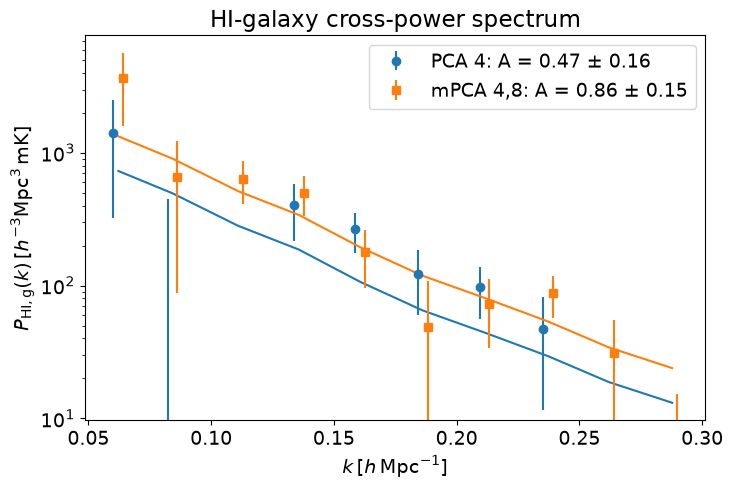

In [10]:
plt.figure(figsize=(8, 5))
for (name, r), mk, dx in zip(res.items(), ['o', 's'], [-0.002, 0.002]):
    line = plt.errorbar(r['k'] / ps.h + dx, r['p'] * ps.h**3 * 1e3, yerr=r['sigma'] * ps.h**3 * 1e3,
                        ls='none', marker=mk, label=f"{name}: A = {r['A']:.2f} ± {r['sigma_A']:.2f}")
    plt.plot(r['k'] / ps.h, r['A'] * template * ps.h**3 * 1e3, color=line[0].get_color())
plt.yscale('log')
plt.xlabel(r'$k\,[h\,{\rm Mpc}^{-1}]$')
plt.ylabel(r'$P_{\rm HI,g}(k)\,[h^{-3}{\rm Mpc^3\,mK}]$')
plt.title('HI-galaxy cross-power spectrum')
plt.legend()

Comparison with the paper (Table 1, Gaussian errors, no transfer function):

In [11]:
paper = {f'PCA {N_fg}': (0.50, 0.16), f'mPCA {N_L},{N_S}': (0.93, 0.17)}
for name, r in res.items():
    print(f"{name:10s} this page: {r['A']:.2f} ± {r['sigma_A']:.2f}    paper: {paper[name][0]:.2f} ± {paper[name][1]:.2f}")

PCA 4      this page: 0.47 ± 0.16    paper: 0.50 ± 0.16
mPCA 4,8   this page: 0.86 ± 0.15    paper: 0.93 ± 0.17


Remaining differences from the paper: the WiggleZ 11h catalogue (the paper used a version with about 9 % more
galaxies in the CF), the selection function if `WiggleZ_selection.npy` is not available (see above), and the
power-spectrum code.